# Extract Tourist Attractions in Black Forest National Park

A hybrid OpenStreetMap + Google Maps workflow:

1. **Extract the park boundary** from OpenStreetMap (`Nationalpark Schwarzwald`, OSM relation
   [`3412590`](https://www.openstreetmap.org/relation/3412590)).
2. **Find candidate attractions inside the park** from OSM using the `tourism` tag
   (`attraction` plus related values). This gives a small, targeted list of points.
3. **Enrich each point with Google Maps** using the Places API (New) *Text Search*, spending
   one API call per known location instead of scanning the whole park with a search grid.

| Output file | Contents |
|---|---|
| `black_forest_national_park.gpkg` | Park boundary polygon (from OSM) |
| `tourist_attractions.gpkg` | Candidate attraction points (from OSM) |
| `tourist_attractions_googlemaps.gpkg` | The same points enriched with Google Maps fields |

## Extracting Footfall data

The Google Maps Platform APIs do **not** expose "popular times", live busyness, or visit-duration data. The available popularity signals are `rating` and `userRatingCount` (review count), which we collect below. Actual foot-traffic would need a separate source (park visitor counters, Strava Metro, a mobility-data vendor, or scraping as mentioned below

## Other techniques for popularity / footfall data

The Places API only returns `rating` and `userRatingCount`. For actual visitor volumes,
consider these sources, roughly best to worst for a German national park:

**1. Park visitor monitoring (authoritative).** Nationalpark Schwarzwald runs automated
trail counters (light-barrier / pyroelectric sensors) and periodic visitor surveys. Request
counter data or the published monitoring reports from the park administration. This is the
only source calibrated to real people-counts.

**2. [Strava Metro](https://metro.strava.com).** Aggregated, anonymised running / hiking /
cycling activity per trail segment. Free for public agencies, universities, and non-profits.
Good relative volumes and seasonality for a hiking area; biased toward fitness users and
undercounts casual visitors.

**3. Mobile-network / GPS mobility data (commercial).** Vendors such as Motiontag,
Teralytics, Telefonica (Germany), or app-SDK panels like Placer.ai, Advan, and Veraset.
They provide visit counts, dwell time, and home locations. Expensive, licensed, and coverage
in a sparsely populated forest is thin - these products are built for retail catchments.

**4. Proxy signals you can build yourself.**

- **Geotagged-photo density** - Flickr API (`flickr.photos.search` with a bbox and
  `min_taken_date`), Mapillary, or Wikimedia Commons geosearch. Count photos per POI per
  month as a visitation proxy.
- **Review cadence** - the count and timestamps of Google reviews (`userRatingCount`, or the
  `reviews` field) as a rough trend over time.
- **Wikipedia pageviews** - the Wikimedia REST API, a proxy for public interest:

For a defensible analysis, combine the **OSM + Google inventory from this notebook** with
**Strava Metro** and/or the **park's own counter data**, and treat scraped popular-times as
illustrative only.

## Setup

In [ ]:
import os
import time
import json

import requests
import pandas as pd
import geopandas as gpd
import osmnx as ox

In [ ]:
# Black Forest National Park - OSM relation id
PARK_OSM_ID = 'R3412590'

# tourism tag values to treat as "tourist attractions"
TOURISM_VALUES = [
    'attraction', 'viewpoint', 'museum', 'artwork',
    'gallery', 'theme_park', 'zoo', 'aquarium',
]

boundary_file = 'black_forest_national_park.gpkg'
attractions_file = 'tourist_attractions.gpkg'
enriched_file = 'tourist_attractions_popularity.gpkg'

# Get a free demo key at https://mapsplatform.google.com/maps-demo-key/
GOOGLE_MAPS_API_KEY = '<enter your api key>'

## Step 1: Extract the park boundary from OpenStreetMap

`osmnx.geocode_to_gdf` fetches the geometry of a single OSM object by id. We keep just the
polygon and write it to a GeoPackage.

In [ ]:
boundary = ox.geocode_to_gdf(PARK_OSM_ID, by_osmid=True)

boundary = boundary[['geometry']].copy()
boundary['name'] = 'Nationalpark Schwarzwald'
boundary['osm_id'] = PARK_OSM_ID
boundary

,geometry,name,osm_id
0,"MULTIPOLYGON (((8.18476 48.52949, 8.18478 48.5...",Nationalpark Schwarzwald,R3412590


In [ ]:
# save the extracted boundary to a GeoPackage
# remove any existing file first so re-runs don't stack up layers
if os.path.exists(boundary_file):
    os.remove(boundary_file)
boundary.to_file(boundary_file, layer='park_boundary', driver='GPKG')
print(f'Saved park boundary to {boundary_file}')

Saved park boundary to black_forest_national_park.gpkg


<Axes: >

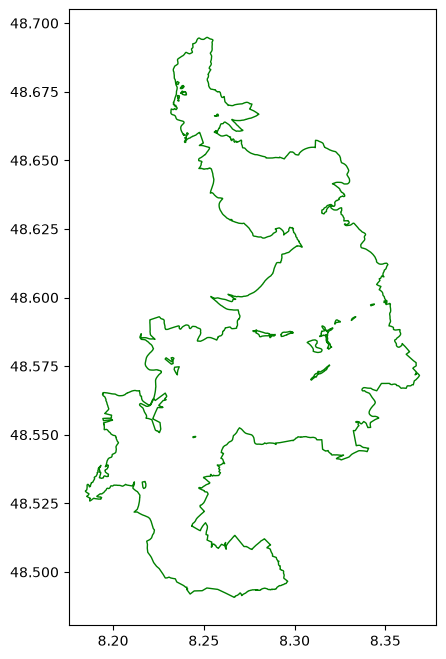

In [ ]:
boundary.plot(figsize=(6, 8), facecolor='none', edgecolor='green')

## Step 2: Find candidate attractions inside the park

`osmnx.features_from_polygon` downloads all OSM features within the boundary that carry one
of our `tourism` tag values. Some features are mapped as polygons (a museum building, a
theme park); we replace those with an interior point so the output layer is all points.

You can also manually collect data from websites such as https://www.black-forest-travel.com/

In [ ]:
park_polygon = boundary.geometry.iloc[0]

features = ox.features_from_polygon(park_polygon, {'tourism': TOURISM_VALUES})

print(f'Found {len(features)} OSM features')
features['tourism'].value_counts()

Found 44 OSM features


tourism
viewpoint     38
attraction     5
zoo            1
Name: count, dtype: int64

In [ ]:
# keep a few useful tag columns, when present
tag_columns = ['name', 'tourism', 'website', 'wikidata', 'wikipedia',
               'opening_hours', 'description']

attractions = features.reset_index()
tag_columns = [c for c in tag_columns if c in attractions.columns]
attractions = attractions[['element', 'id'] + tag_columns + ['geometry']]
attractions = attractions.rename(columns={'element': 'osm_type', 'id': 'osm_id'})

# represent non-point features by an interior point
not_point = attractions.geometry.geom_type != 'Point'
attractions.loc[not_point, 'geometry'] = \
    attractions.loc[not_point, 'geometry'].representative_point()

attractions = gpd.GeoDataFrame(attractions, geometry='geometry', crs='EPSG:4326')
if os.path.exists(attractions_file):
    os.remove(attractions_file)
attractions.to_file(attractions_file, layer='tourist_attractions', driver='GPKG')
print(f'Saved {len(attractions)} attraction points to {attractions_file}')
attractions.head(10)

Saved 44 attraction points to tourist_attractions.gpkg


,osm_type,osm_id,name,tourism,wikidata,wikipedia,opening_hours,geometry
0,node,260481197,Schliffkopf,viewpoint,Q881889,de:Schliffkopf,NaN,POINT (8.21519 48.53535)
1,node,272858749,Huzenbacher Seeblick,viewpoint,NaN,NaN,NaN,POINT (8.3453 48.57184)
2,node,288673540,Märchenwiese,viewpoint,NaN,NaN,NaN,POINT (8.2369 48.67187)
3,node,291426905,Achertal-Blick,viewpoint,NaN,NaN,NaN,POINT (8.22163 48.57665)
4,node,292166555,Traubwasserfall,attraction,NaN,NaN,NaN,POINT (8.24201 48.54837)
5,node,292757831,Studentenfelsen,viewpoint,NaN,NaN,NaN,POINT (8.19008 48.53043)
6,node,297348245,NaN,viewpoint,NaN,NaN,NaN,POINT (8.23049 48.54753)
7,node,304083984,NaN,viewpoint,NaN,NaN,NaN,POINT (8.19904 48.56109)
8,node,307809354,NaN,viewpoint,NaN,NaN,NaN,POINT (8.19711 48.56225)
9,node,307809365,NaN,viewpoint,NaN,NaN,NaN,POINT (8.19824 48.56175)


<Axes: >

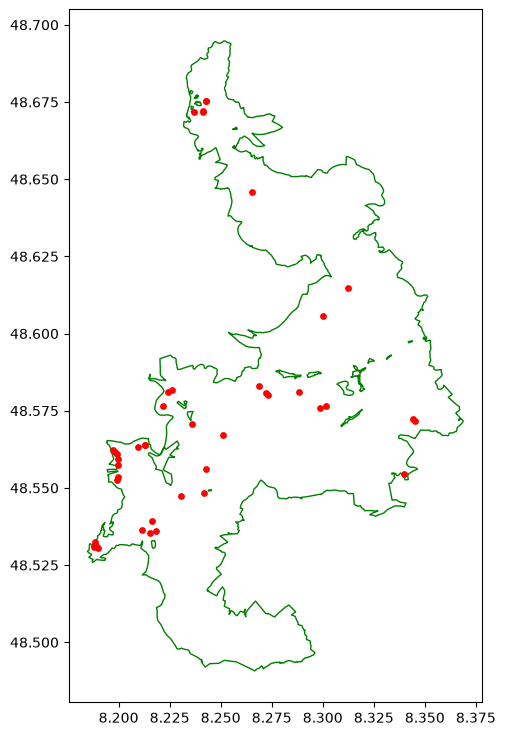

In [ ]:
ax = boundary.plot(figsize=(7, 9), facecolor='none', edgecolor='green')
attractions.plot(ax=ax, color='red', markersize=15)

## Step 3: Enrich one attraction with the Google Maps Places API

We use the **Places API (New)** *Text Search* endpoint (`places:searchText`). For each
attraction we send its OSM `name` as the query, biased to a circle around the OSM
coordinates, and request a field mask. We keep the first candidate and record its distance
from the OSM point as a match-quality check. Features without a name are skipped (there is
nothing to search for).

Requirements:

- **Places API (New)** must be enabled for the Cloud project that owns the API key
  (`console.cloud.google.com` -> APIs & Services -> Enable APIs -> "Places API (New)").
- Requesting `rating` / `userRatingCount` puts each call in the *Text Search Enterprise*
  billing SKU. Check current pricing before running the full list.

In [ ]:
PLACES_URL = 'https://places.googleapis.com/v1/places:searchText'

# https://developers.google.com/maps/documentation/places/web-service/text-search#fieldmask
FIELD_MASK = ','.join([
    'places.id',
    'places.displayName',
    'places.formattedAddress',
    'places.location',
    'places.primaryType',
    'places.types',
    'places.rating',
    'places.userRatingCount',
    'places.priceLevel',
    'places.businessStatus',
    'places.googleMapsUri',
    'places.regularOpeningHours',
    'places.editorialSummary',
])


def haversine_m(lat1, lon1, lat2, lon2):
    """Great-circle distance in metres."""
    import math
    r = 6371000
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp = math.radians(lat2 - lat1)
    dl = math.radians(lon2 - lon1)
    a = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * r * math.asin(math.sqrt(a))


def fetch_google_place(name, lat, lon, radius=800):
    """Look up one place by name near (lat, lon). Returns (status_code, response_json)."""
    body = {
        'textQuery': name,
        'locationBias': {
            'circle': {
                'center': {'latitude': lat, 'longitude': lon},
                'radius': float(radius),
            }
        },
        'maxResultCount': 1,
        'languageCode': 'en',
    }
    headers = {
        'X-Goog-Api-Key': GOOGLE_MAPS_API_KEY,
        'X-Goog-FieldMask': FIELD_MASK,
        'Content-Type': 'application/json',
    }
    response = requests.post(PLACES_URL, headers=headers, json=body, timeout=30)
    return response.status_code, response.json()

## Step 4: Extract Data

The cell below loops over every named attraction and calls the Places API once each, with a
one-second pause between calls.

In [ ]:
def parse_place(place, osm_lat, osm_lon):
    """Flatten the fields we care about from a Places API result."""
    loc = place.get('location', {})
    g_lat, g_lon = loc.get('latitude'), loc.get('longitude')
    return {
        'google_place_id': place.get('id'),
        'google_name': place.get('displayName', {}).get('text'),
        'google_address': place.get('formattedAddress'),
        'google_primary_type': place.get('primaryType'),
        'rating': place.get('rating'),
        'user_rating_count': place.get('userRatingCount'),
        'price_level': place.get('priceLevel'),
        'business_status': place.get('businessStatus'),
        'google_maps_uri': place.get('googleMapsUri'),
        'google_lat': g_lat,
        'google_lon': g_lon,
        'match_distance_m': (round(haversine_m(osm_lat, osm_lon, g_lat, g_lon), 1)
                             if g_lat is not None else None),
    }


records = []
for _, row in named.iterrows():
    lat, lon = row.geometry.y, row.geometry.x
    print('Looking up:', row['name'])
    try:
        status, payload = fetch_google_place(row['name'], lat, lon)
        places = payload.get('places', []) if status == 200 else []
        record = parse_place(places[0], lat, lon) if places else {}
        if status != 200:
            record['error'] = payload.get('error', {}).get('message', f'HTTP {status}')
    except Exception as e:
        record = {'error': str(e)}
    record['osm_id'] = row['osm_id']
    record['name'] = row['name']
    records.append(record)
    time.sleep(1)

results_df = pd.DataFrame(records)
matched = results_df['google_place_id'].notna().sum() if 'google_place_id' in results_df else 0
print(f'\nDone. {matched} of {len(results_df)} attractions matched to a Google place.')

Looking up: Schliffkopf
Looking up: Huzenbacher Seeblick
Looking up: Märchenwiese
Looking up: Achertal-Blick
Looking up: Traubwasserfall
Looking up: Studentenfelsen
Looking up: Schurmseeblick
Looking up: Buchendom
Looking up: Wollsackfelsen
Looking up: Wattenstein
Looking up: Engelskanzel
Looking up: Adlerhorst
Looking up: Wildseeblick
Looking up: Allerheiligen-Wasserfälle
Looking up: Blick auf Herrenwies und St. Antonius
Looking up: Fliegerbombe
Looking up: Hirschgehege
Looking up: Wollsackfelsen

Done. 17 of 18 attractions matched to a Google place.


In [ ]:
results_df

,google_place_id,google_name,google_address,google_primary_type,rating,user_rating_count,price_level,business_status,google_maps_uri,google_lat,google_lon,match_distance_m,osm_id,name
0,ChIJpcCQQMMul0cRB3Z-8XU2iWc,Schliffkopf,"Schliffkopf, 77728 Oppenau, Germany",mountain_peak,4.6,108.0,NaN,NaN,https://maps.google.com/?cid=74605541379066076...,48.535556,8.215556,35.5,260481197,Schliffkopf
1,ChIJqzuS1Hgwl0cRk0MBMRNNxtI,Huzenbacher Seeblick,"Schifferstraße 116, 72270 Baiersbronn, Germany",hiking_area,4.7,147.0,NaN,OPERATIONAL,https://maps.google.com/?cid=15187911538175460...,48.571799,8.345116,14.3,272858749,Huzenbacher Seeblick
2,ChIJ168dOwAdl0cRtBOi5oHTIoU,Märchenwiese Muggensturm,"Am Freizeitgelände 7, 76461 Muggensturm, Germany",garden,4.0,2.0,NaN,OPERATIONAL,https://maps.google.com/?cid=95934627111262012...,48.866961,8.286773,21998.9,288673540,Märchenwiese
3,ChIJNe2uwRbYlkcRwl47IARUvPQ,Achertalblick,"Unnamed Road, 77855 Achern, Germany",observation_deck,4.7,18.0,NaN,OPERATIONAL,https://maps.google.com/?cid=17635062617573383...,48.609516,8.097057,9863.5,291426905,Achertal-Blick
4,ChIJh-1kfFL4c0cRBUQQYIp_qgc,Traunfall,"Traunfall 4661, 4693 Desselbrunn, Austria",tourist_attraction,4.7,4382.0,NaN,OPERATIONAL,https://maps.google.com/?cid=55239413660020019...,48.016365,13.799395,415360.6,292166555,Traubwasserfall
5,ChIJSweLynkpl0cRghv2IFcM_QY,Aussichtsplattform Studentenfelsen,"K5370, 77728 Oppenau, Germany",observation_deck,4.7,23.0,NaN,OPERATIONAL,https://maps.google.com/?cid=50357230169005145...,48.530493,8.190498,31.3,292757831,Studentenfelsen
6,ChIJmQQlBywll0cRyIE4pyDbkrw,Schurmseeblick,"76596 Forbach, Germany",observation_deck,4.7,43.0,NaN,OPERATIONAL,https://maps.google.com/?cid=13588163959021142...,48.615130,8.313078,55.7,343605652,Schurmseeblick
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,549142180,Buchendom
8,ChIJOUe2edgjl0cRxEWO272ehhs,Wollsackfelsen,"Herrenwies, 76596 Forbach, Germany",tourist_attraction,4.6,8.0,NaN,OPERATIONAL,https://maps.google.com/?cid=19834472241728240...,48.675377,8.242992,2.5,549142190,Wollsackfelsen
9,ChIJFZnuFgApl0cRtAS2iRuuUFU,Aussichtspunkt Wattenstein (oberhalb Engelskan...,"G5JQ+H3, 77728 Oppenau, Germany",tourist_attraction,5.0,3.0,NaN,OPERATIONAL,https://maps.google.com/?cid=61476049246584844...,48.531498,8.187695,114.3,763052001,Wattenstein


## Step 5: Save the enriched layer

In [ ]:
if results_df is not None:
    enriched = named.merge(results_df.drop(columns='name'), on='osm_id', how='left')
    enriched = gpd.GeoDataFrame(enriched, geometry='geometry', crs='EPSG:4326')
    if os.path.exists(enriched_file):
        os.remove(enriched_file)
    enriched.to_file(enriched_file, layer='tourist_attractions', driver='GPKG')
    print(f'Saved {len(enriched)} enriched features to {enriched_file}')
    enriched.head()

Saved 18 enriched features to tourist_attractions_popularity.gpkg


## Interactive map

Points shown over the park boundary. Once the Google enrichment has run, the tooltip also
shows the rating, review count, and how far the matched Google place was from the OSM point.

In [ ]:
if results_df is not None:
    layer = enriched
    tooltip = ['name', 'tourism', 'rating', 'user_rating_count', 'match_distance_m']
else:
    layer = attractions
    tooltip = ['name', 'tourism']

m = layer.explore(
    tooltip=tooltip,
    marker_kwds={'radius': 5},
    color='red',
    tiles='CartoDB positron',
)
boundary.explore(m=m, style_kwds={'fillOpacity': 0.05, 'color': 'green'})
m